# Phase 2 — Transformer encoder (08)

Issue #60. The Transformer encoder (Vaswani et al., 2017) projects each cycle to `d_model` units and adds a sinusoidal position code, so the order of cycles is known. Self-attention then lets every cycle in the window look at every other cycle in one step. The LSTM passes information along the sequence instead, and the temporal CNN through a fixed receptive field. FD001 has only about 18,000 training windows, so the model stays small: one or two pre-norm layers of 32 or 64 units, pooled by averaging over the window.

**Protocol** (`CONTRIBUTING.md` §8, shared trainer from #53):

- The same 3 engine-grouped folds as Phase 1 (seed 42).
- Inside each fold, 20% of the training engines are held out for early stopping only.
- Training labels are capped at 125, the cap #55 chose from training engines. These runs used 125 before #55 closed, and its choice kept it, so they stand as they are.
- Every held-out cycle is scored against the true, uncapped RUL.
- The **selection metric** is the RMSE on held-out cycles whose true RUL is at most K = 130, the threshold #55 set from training engines. Each run's held-out predictions are kept, so the metric can be recomputed for another K.

**Cross-validation only.** The official test set isn't read here. It runs once, after the model freeze, in #71.

In [1]:
from itertools import product
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.data.load import load_subset
from rul.models.registry import build_model
from rul.training.config import apply_overrides, load_config, run_cv
from rul.training.runs import save_cv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
GRID_DIR = ROOT / "results/models/grids/transformer"  # per-run cache (gitignored); delete it to rerun the grid
FIGURES = ROOT / "results/figures"

train = load_subset("FD001", data_dir=ROOT / "data/raw/CMAPSSData").train
base = load_config(ROOT / "configs/transformer.yaml")
print(f"{train['unit'].nunique()} training engines, {len(train):,} cycles")
print({k: base[k] for k in ("target", "selection", "cv", "inputs", "training")})

100 training engines, 20,631 cycles
{'target': {'cap': 125}, 'selection': {'max_true_rul': 130}, 'cv': {'n_splits': 3, 'split_seed': 42, 'holdout_size': 0.2}, 'inputs': {'type': 'windows', 'window': 30, 'stride': 1, 'n_regimes': 1, 'include_cycle': False}, 'training': {'epochs': 100, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 0.0, 'grad_clip': 1.0, 'scheduler': 'cosine', 'patience': 10, 'loss': 'mse', 'device': 'cpu', 'seed': 42}}


## 1. Grid

Model width `d_model` (32 or 64), attention heads (2 or 4), layers (1 or 2) and dropout (0.1 or 0.3): 16 settings. The feed-forward block is twice `d_model` wide.

Everything else stays at the shared base settings: window 30, Adam at 1e-3, batch 256, cosine schedule over at most 100 epochs, and patience 10. Each setting is cross-validated on the 3 folds and cached under `results/models/grids/transformer/`, so rerunning the notebook reuses finished runs. A full run is deterministic for a given seed.

In [2]:
GRID = [
    {"d_model": d_model, "n_heads": heads, "num_layers": layers, "dropout": dropout}
    for d_model, heads, layers, dropout in product((32, 64), (2, 4), (1, 2), (0.1, 0.3))
]


def run_key(params: dict) -> str:
    return "_".join(f"{k}{v}" for k, v in params.items())


def cached_cv(params: dict) -> dict:
    """Cross-validate one setting, or load it if it already ran."""
    path = GRID_DIR / f"{run_key(params)}.json"
    if not path.exists():
        config = apply_overrides(base, [f"model.{k}={v}" for k, v in params.items()])
        cv = run_cv(config, train)
        GRID_DIR.mkdir(parents=True, exist_ok=True)
        cv.predictions.to_csv(path.with_suffix(".csv"), index=False)
        path.write_text(json.dumps({"params": params, **cv.to_dict()}))
    return json.loads(path.read_text())


def model_of(params: dict):
    return build_model({"type": "transformer", **params}, {"n_features": 15})


grid_runs = [cached_cv(params) for params in GRID]
grid = pd.DataFrame([
    {**run["params"],
     **{},
     "parameters": sum(w.numel() for w in model_of(run["params"]).parameters()),
     "selection_rmse": run["summary"]["selection_rmse"]["mean"],
     "selection_std": run["summary"]["selection_rmse"]["std"],
     "all_cycle_rmse": run["summary"]["rmse"]["mean"],
     "best_epochs": [f["best_epoch"] for f in run["folds"]],
     "minutes": run["seconds"] / 60}
    for run in grid_runs
]).sort_values("selection_rmse").reset_index(drop=True)
grid.to_csv(ROOT / "results/metrics/fd001_transformer_grid.csv", index=False)
display(grid.round(2))

,d_model,n_heads,num_layers,dropout,parameters,selection_rmse,selection_std,all_cycle_rmse,best_epochs,minutes
0,64,4,1,0.1,34689,15.16,0.99,46.89,"[5, 10, 13]",1.74
1,64,4,2,0.1,68161,15.35,0.61,46.65,"[10, 4, 8]",3.12
2,64,2,2,0.1,68161,15.50,1.37,46.20,"[8, 4, 7]",2.28
3,64,2,2,0.3,68161,15.51,2.05,45.67,"[6, 11, 9]",2.65
4,64,2,1,0.1,34689,15.55,1.75,46.65,"[6, 8, 9]",1.39
5,32,4,1,0.1,9153,15.59,0.23,46.75,"[33, 17, 13]",2.07
6,32,2,2,0.1,17697,15.61,0.93,46.39,"[5, 16, 12]",1.83
7,32,2,1,0.1,9153,15.91,0.49,46.92,"[17, 18, 29]",1.50
8,32,4,2,0.1,17697,15.96,0.67,45.85,"[20, 17, 10]",3.24
9,32,4,1,0.3,9153,16.07,0.86,45.12,"[23, 22, 23]",2.19


## 2. Choose the setting

The setting with the lowest mean selection RMSE across the 3 folds sets the bar. A gap smaller than that setting's fold-to-fold standard deviation isn't a real difference, so among the settings within one standard deviation of the best, the one with the fewest parameters is chosen.

In [3]:
PARAMS = ["d_model", "n_heads", "num_layers", "dropout"]
best = grid.iloc[0]
close = grid[grid["selection_rmse"] <= best["selection_rmse"] + best["selection_std"]]
chosen = close.sort_values(["parameters", "selection_rmse"]).iloc[0]
CHOSEN = {k: (float(chosen[k]) if k == "dropout" else int(chosen[k])) for k in PARAMS}
print(f"lowest selection RMSE: {best['selection_rmse']:.2f} ± {best['selection_std']:.2f} ({best['parameters']:,} parameters)")
print(f"settings within one standard deviation: {len(close)}; chosen (fewest parameters): {CHOSEN}, "
      f"{chosen['selection_rmse']:.2f} ± {chosen['selection_std']:.2f}, {int(chosen['parameters']):,} parameters")

lowest selection RMSE: 15.16 ± 0.99 (34,689 parameters)
settings within one standard deviation: 11; chosen (fewest parameters): {'d_model': 32, 'n_heads': 4, 'num_layers': 1, 'dropout': 0.1}, 15.59 ± 0.23, 9,153 parameters


## 3. Chosen setting: capped and uncapped targets

The chosen setting is rerun and saved for both targets:

- **Capped at 125:** `results/metrics/fd001_cv_transformer.json`
- **Uncapped:** `fd001_cv_transformer_uncapped.json`

Each run also saves every held-out cycle's prediction (`*_predictions.csv`), for the hybrid study (#68) and validation (#72). The capped rerun has to match its grid run exactly, which checks that the seed fixes the result.

In [4]:
final_config = apply_overrides(base, [f"model.{k}={v}" for k, v in CHOSEN.items()])
runs = {
    "capped at 125": (final_config, "fd001_cv_transformer"),
    "uncapped": (apply_overrides(final_config, ["target.cap=null"]), "fd001_cv_transformer_uncapped"),
}
results = {}
for label, (config, name) in runs.items():
    results[label] = run_cv(config, train)
    save_cv(name, results[label], meta={"name": name, "subset": "FD001", "config": config})

grid_value = grid.loc[(grid[PARAMS] == pd.Series(CHOSEN)).all(axis=1), "selection_rmse"].item()
assert np.isclose(results["capped at 125"].summary()["selection_rmse"]["mean"], grid_value)

rows = []
for label, cv in results.items():
    s = cv.summary()
    rows.append({"target": label,
                 "selection RMSE": f"{s['selection_rmse']['mean']:.2f} ± {s['selection_rmse']['std']:.2f}",
                 "all-cycle RMSE": f"{s['rmse']['mean']:.2f} ± {s['rmse']['std']:.2f}",
                 "all-cycle MAE": f"{s['mae']['mean']:.2f}",
                 "best epochs": [f.best_epoch for f in cv.folds]})
display(pd.DataFrame(rows))

,target,selection RMSE,all-cycle RMSE,all-cycle MAE,best epochs
0,capped at 125,15.59 ± 0.23,46.75 ± 4.18,30.01,"[33, 17, 13]"
1,uncapped,30.99 ± 3.23,40.55 ± 2.41,28.68,"[8, 12, 16]"


**Reading the two targets.** All-cycle RMSE punishes the capped model on early cycles, where the true RUL can be over 300 but the model predicts about 125. The official test hardly scores cycles like that, because test engines are scored at their last cycle. The selection metric only looks at cycles near failure, which is where the test engines are, so it is the fair comparison here. The stage-wise table shows where each target wins (late ≤ 50 < mid ≤ 100 < early, by true RUL).

In [5]:
def stage_rows(cv, label):
    return [{"target": label, "fold": f.fold, "stage": stage, "RMSE": s["rmse"]}
            for f in cv.folds for stage, s in f.scores["all_cycles"]["by_stage"].items()]

stages = pd.DataFrame([r for label, cv in results.items() for r in stage_rows(cv, label)])
display(stages.pivot_table(index="stage", columns="target", values="RMSE", aggfunc="mean")
        .loc[["late", "mid", "early"]].round(2))

target,capped at 125,uncapped
stage,,
late,9.35,13.89
mid,20.75,36.22
early,63.50,49.94


## 4. Learning curves (capped target)

Training RMSE against the early-stopping holdout for each fold. The dashed line is the epoch whose weights are kept.

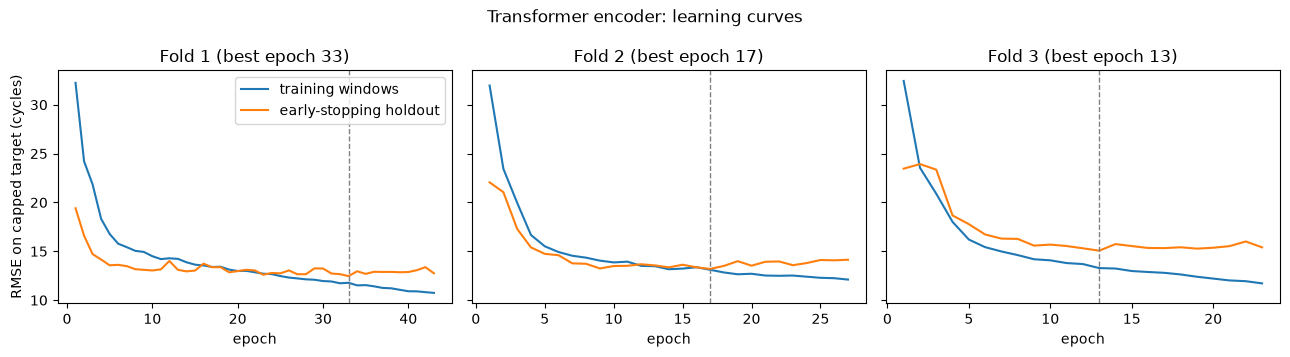

In [6]:
capped = results["capped at 125"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, fold in zip(axes, capped.folds):
    hist = pd.DataFrame(fold.history)
    ax.plot(hist["epoch"], np.sqrt(hist["train_loss"]) * 125, label="training windows")
    ax.plot(hist["epoch"], hist["val_rmse"], label="early-stopping holdout")
    ax.axvline(fold.best_epoch, color="grey", ls="--", lw=1)
    ax.set(title=f"Fold {fold.fold} (best epoch {fold.best_epoch})", xlabel="epoch")
axes[0].set_ylabel("RMSE on capped target (cycles)")
axes[0].legend()
fig.suptitle("Transformer encoder: learning curves")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_transformer_learning_curves.png", dpi=150)
plt.show()

## 5. Held-out predictions

Every held-out cycle, coloured by fold. The shaded band is what the selection metric scores.

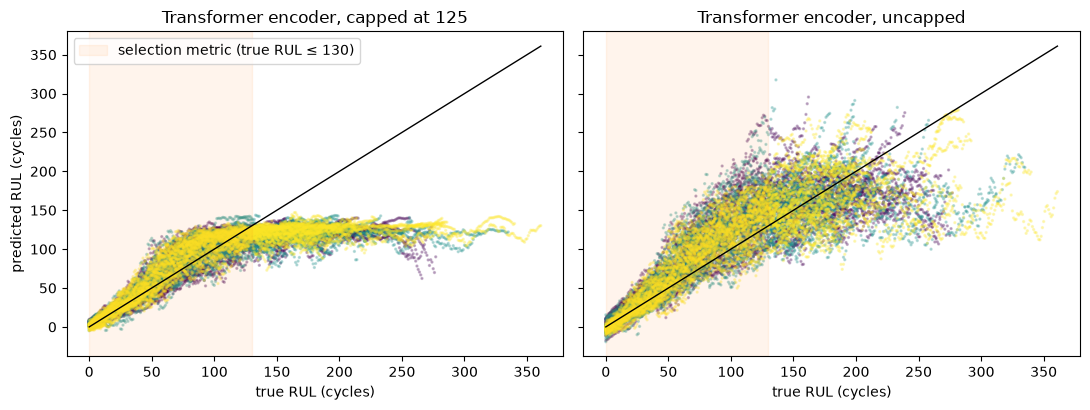

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (label, cv) in zip(axes, results.items()):
    p = cv.predictions
    ax.scatter(p["rul"], p["prediction"], s=2, alpha=0.25, c=p["fold"], cmap="viridis")
    lim = [0, p["rul"].max()]
    ax.plot(lim, lim, color="black", lw=1)
    ax.axvspan(0, 130, color="tab:orange", alpha=0.08, label="selection metric (true RUL ≤ 130)")
    ax.set(title=f"Transformer encoder, {label}", xlabel="true RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_transformer_heldout_predictions.png", dpi=150)
plt.show()

## 6. Where the model attends

`TransformerEncoder.attention(x)` returns every layer's per-head attention weights for #73. To illustrate them, the chosen setting is refitted on all 100 training engines for its median best epoch, exactly as the final model will be. The checkpoint goes to `results/models/`, which git ignores.

The maps below are averaged over heads and over windows from training engines at two points in life: healthy (true RUL above 150) and near failure (true RUL at most 30). Row i shows how much cycle i of the window attends to each cycle. The last row (the newest cycle) is the most useful one to read. This is a description of the trained model, not a score: #73 does the full attribution study on the final models.

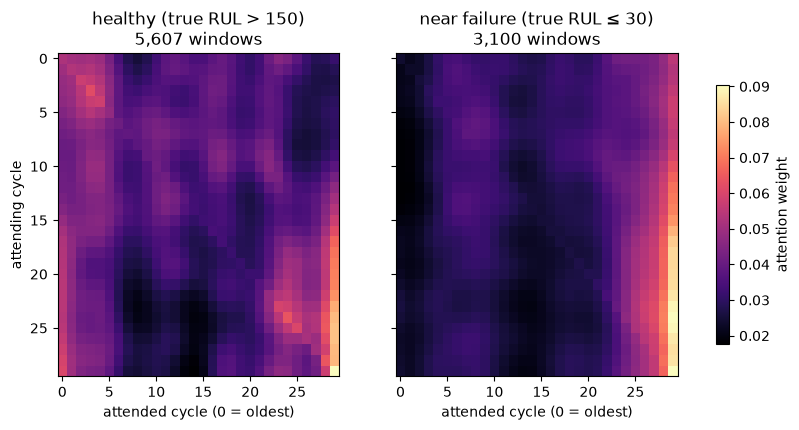

,healthy (true RUL > 150),near failure (true RUL ≤ 30)
oldest 10 cycles,0.341,0.278
middle 10,0.250,0.244
newest 10,0.409,0.478


In [8]:
import torch
from rul.data.labels import add_train_rul
from rul.training.config import run_parts
from rul.training.runs import refit

parts = run_parts(final_config)
model, fit_result = refit(train, parts.make_model, parts.make_inputs, parts.train_config,
                          cap=parts.cv_kwargs["cap"], epochs=results["capped at 125"].median_best_epoch)
model.save(ROOT / "results/models/fd001_transformer_seed42.pt", meta={"config": final_config})

labelled = add_train_rul(train)
batch = model.inputs.transform(labelled, target="rul", stride=1)
encoder = model.model.encoder.eval()
groups = {"healthy (true RUL > 150)": batch.y > 150, "near failure (true RUL ≤ 30)": batch.y <= 30}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, (name, mask) in zip(axes, groups.items()):
    windows = torch.from_numpy(batch.inputs[0][mask][:2000])
    attn = encoder.attention(windows)[-1].mean(dim=(0, 1)).numpy()  # last layer, averaged over windows and heads
    im = ax.imshow(attn, cmap="magma", aspect="auto")
    ax.set(title=f"{name}\n{int(mask.sum()):,} windows", xlabel="attended cycle (0 = oldest)")
axes[0].set_ylabel("attending cycle")
fig.colorbar(im, ax=axes, shrink=0.8, label="attention weight")
fig.savefig(FIGURES / "fd001_transformer_attention.png", dpi=150, bbox_inches="tight")
plt.show()

newest = {name: encoder.attention(torch.from_numpy(batch.inputs[0][mask][:2000]))[-1].mean(dim=(0, 1))[-1].numpy()
          for name, mask in groups.items()}
display(pd.DataFrame({name: [w[:10].sum(), w[10:20].sum(), w[20:].sum()] for name, w in newest.items()},
                     index=["oldest 10 cycles", "middle 10", "newest 10"]).round(3))

## Summary

- **Chosen setting:** `d_model` 32, 4 heads, one layer, dropout 0.1. Selection RMSE 15.59 ± 0.23 over the 3 folds, with 9,153 parameters. The lowest score was 15.16 ± 0.99 (`d_model` 64, 4 heads, one layer, 34,689 parameters). Its fold-to-fold spread is wide, so 11 of the 16 settings fall within one standard deviation of it, and the smallest of them is chosen.
- **Dropout:** 0.1 scored better than 0.3 in all 8 pairs. For `d_model` 64, 2 heads, 2 layers, the gap is only 0.01.
- **Against the LSTM (#58):** 15.59 ± 0.23 against 15.78 ± 0.44, with less than half the parameters. The gap is smaller than either model's fold spread, so on these folds the two are level.
- **Target:** capped beats uncapped near failure (selection RMSE 15.59 against 30.99; late-stage RMSE 9.35 against 13.89).
- **Attention:** in both groups, every cycle attends most to the newest one or two cycles. Near failure, that pull gets stronger: the newest cycle puts 0.48 of its attention on the newest 10 cycles, against 0.41 in healthy windows. #73 studies attributions properly on the final models.
- `configs/transformer.yaml` holds the chosen setting. These are cross-validation scores; the official test runs once, in #71.